In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [63]:
modules = pd.read_csv("modules.csv")
metrics = pd.read_csv("metrics.csv")
defects = pd.read_csv("defects.csv")
commits = pd.read_csv("commits.csv")
releases = pd.read_csv("releases.csv")

In [ ]:
print("Modules:", modules.shape)
print("Metrics:", metrics.shape)
print("Defects:", defects.shape)
print("Commits:", commits.shape)
print("Releases:", releases.shape)

In [64]:
display(modules.head())
display(metrics.head())
display(defects.head())
display(commits.head())
display(releases.head())

,module,component,language,size
0,MOD_001,Notifications,Java,13771
1,MOD_002,Search,Java,1463
2,MOD_003,Analytics,C++,2798
3,MOD_004,User Management,JavaScript,8794
4,MOD_005,Notifications,JavaScript,12437


,module,release,complexity,coupling,churn,test_coverage
0,MOD_001,R2025.1,24.67,8.38,127.91,51.24
1,MOD_001,R2025.2,20.31,10.78,231.66,71.67
2,MOD_001,R2025.3,27.98,17.41,132.53,56.74
3,MOD_001,R2025.4,15.48,12.90,250.18,58.81
4,MOD_001,R2026.1,24.66,12.99,172.43,72.04


,defect_id,module,release,defect_count,severity
0,D00001,MOD_001,R2025.1,3,Medium
1,D00002,MOD_001,R2025.2,9,Critical
2,D00003,MOD_001,R2025.3,5,High
3,D00004,MOD_001,R2025.4,5,High
4,D00005,MOD_001,R2026.1,4,Medium


,module,release,commit_count,contributors,changed_lines
0,MOD_001,R2025.1,35,8,182
1,MOD_001,R2025.2,44,5,71
2,MOD_001,R2025.3,46,1,162
3,MOD_001,R2025.4,42,9,143
4,MOD_001,R2026.1,38,6,174


,module,version,release_date
0,MOD_001,R2025.1,2025-01-15
1,MOD_001,R2025.2,2025-03-01
2,MOD_001,R2025.3,2025-04-15
3,MOD_001,R2025.4,2025-05-30
4,MOD_001,R2026.1,2025-07-14


In [65]:
for name, df in {
    "Modules": modules,
    "Metrics": metrics,
    "Defects": defects,
    "Commits": commits,
    "Releases": releases
}.items():

    print("\n", name)
    print(df.columns.tolist())


 Modules
['module', 'component', 'language', 'size']

 Metrics
['module', 'release', 'complexity', 'coupling', 'churn', 'test_coverage']

 Defects
['defect_id', 'module', 'release', 'defect_count', 'severity']

 Commits
['module', 'release', 'commit_count', 'contributors', 'changed_lines']

 Releases
['module', 'version', 'release_date']


In [66]:
for name, df in {
    "Modules": modules,
    "Metrics": metrics,
    "Defects": defects,
    "Commits": commits,
    "Releases": releases
}.items():

    print("\n" + "="*50)
    print(name)
    print("="*50)
    print(df.dtypes)


Modules
module       object
component    object
language     object
size          int64
dtype: object

Metrics
module            object
release           object
complexity       float64
coupling         float64
churn            float64
test_coverage    float64
dtype: object

Defects
defect_id       object
module          object
release         object
defect_count     int64
severity        object
dtype: object

Commits
module           object
release          object
commit_count      int64
contributors      int64
changed_lines     int64
dtype: object

Releases
module          object
version         object
release_date    object
dtype: object


In [67]:
for name, df in {
    "Modules": modules,
    "Metrics": metrics,
    "Defects": defects,
    "Commits": commits,
    "Releases": releases
}.items():

    print("\n" + "="*50)
    print(name)
    print("="*50)
    print(df.dtypes)


Modules
module       object
component    object
language     object
size          int64
dtype: object

Metrics
module            object
release           object
complexity       float64
coupling         float64
churn            float64
test_coverage    float64
dtype: object

Defects
defect_id       object
module          object
release         object
defect_count     int64
severity        object
dtype: object

Commits
module           object
release          object
commit_count      int64
contributors      int64
changed_lines     int64
dtype: object

Releases
module          object
version         object
release_date    object
dtype: object


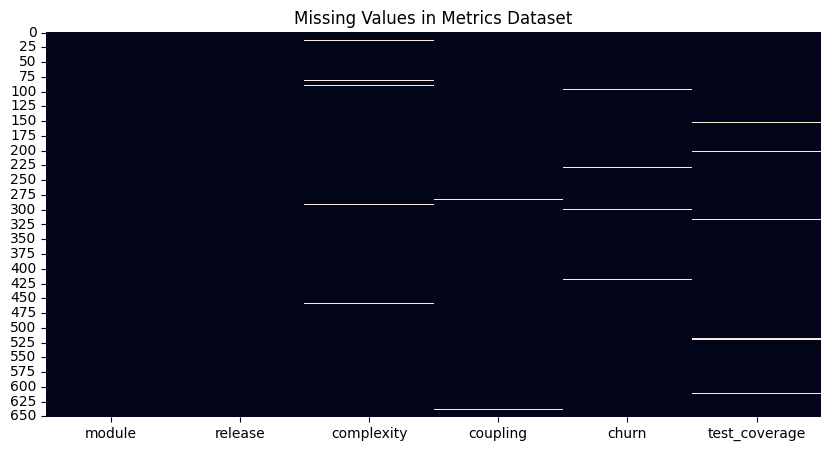

In [68]:
plt.figure(figsize=(10,5))

sns.heatmap(
    metrics.isnull(),
    cbar=False
)

plt.title("Missing Values in Metrics Dataset")
plt.show()

In [70]:
print(
    "Duplicate module-release records:",
    metrics.duplicated(
        subset=["module", "release"]
    ).sum()
)

Duplicate module-release records: 11


In [71]:
for name, df in {
    "Modules": modules,
    "Metrics": metrics,
    "Defects": defects,
    "Commits": commits,
    "Releases": releases
}.items():

    if "module" in df.columns:
        print("\n", name)
        print(df["module"].astype(str).unique()[:20])


 Modules
['MOD_001' 'MOD_002' 'MOD_003' 'MOD_004' 'MOD_005' 'MOD_006' 'MOD_007'
 'MOD_008' 'MOD_009' 'MOD_010' 'MOD_011' 'MOD_012' 'MOD_013' 'MOD_014'
 'MOD_015' 'MOD_016' 'MOD_017' 'MOD_018' 'MOD_019' 'MOD_020']

 Metrics
['MOD_001' 'MOD_002' 'MOD_003' 'MOD_004' 'mod_005 ' 'MOD_005' 'MOD_006'
 'MOD_007' 'MOD_008' 'MOD_009' 'MOD_010' 'MOD_011' 'MOD_012' 'MOD_013'
 'MOD_014' 'MOD_015' 'MOD_016' 'MOD-017' 'MOD_017' 'MOD_018']

 Defects
['MOD_001' 'MOD_002' 'MOD_003' 'MOD_004' 'mod_005 ' 'MOD_005' 'MOD_006'
 'MOD_007' 'MOD_008' 'MOD_009' 'MOD_010' 'MOD_011' 'MOD_012' 'MOD_013'
 'MOD_014' 'MOD_015' 'MOD_016' 'MOD-017' 'MOD_017' 'MOD_018']

 Commits
['MOD_001' 'MOD_002' 'MOD_003' 'MOD_004' 'mod_005 ' 'MOD_005' 'MOD_006'
 'MOD_007' 'MOD_008' 'MOD_009' 'MOD_010' 'MOD_011' 'MOD_012' 'MOD_013'
 'MOD_014' 'MOD_015' 'MOD_016' 'MOD-017' 'MOD_017' 'MOD_018']

 Releases
['MOD_001' 'MOD_002' 'MOD_003' 'MOD_004' 'mod_005 ' 'MOD_005' 'MOD_006'
 'MOD_007' 'MOD_008' 'MOD_009' 'MOD_010' 'MOD_011' 'MOD_01

In [72]:
def clean_module_names(df):
    if "module" in df.columns:
        df["module"] = (
            df["module"]
            .astype(str)
            .str.strip()
            .str.upper()
            .str.replace("-", "_", regex=False)
        )
    return df

In [73]:
modules = clean_module_names(modules)
metrics = clean_module_names(metrics)
defects = clean_module_names(defects)
commits = clean_module_names(commits)
releases = clean_module_names(releases)

In [74]:
metric_columns = [
    "complexity",
    "coupling",
    "churn",
    "test_coverage"
]

metrics_clean = (
    metrics
    .groupby(
        ["module", "release"],
        as_index=False
    )[metric_columns]
    .mean()
)

In [75]:
print(
    "Duplicate module-release records after cleaning:",
    metrics_clean.duplicated(
        subset=["module", "release"]
    ).sum()
)

Duplicate module-release records after cleaning: 0


In [76]:
for col in metric_columns:
    metrics_clean[col] = (
        metrics_clean[col]
        .fillna(metrics_clean[col].median())
    )

In [77]:
print(metrics_clean[metric_columns].isnull().sum())

complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64


In [78]:
Q1 = metrics_clean["complexity"].quantile(0.25)
Q3 = metrics_clean["complexity"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = metrics_clean[
    (metrics_clean["complexity"] < lower) |
    (metrics_clean["complexity"] > upper)
]

print("Number of complexity outliers:", len(outliers))

Number of complexity outliers: 18


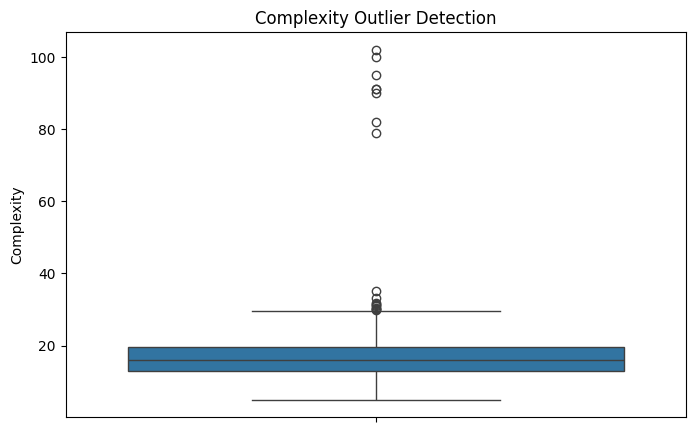

In [79]:
plt.figure(figsize=(8,5))

sns.boxplot(
    y=metrics_clean["complexity"]
)

plt.title("Complexity Outlier Detection")
plt.ylabel("Complexity")

plt.show()

In [80]:
metrics_clean["complexity"] = (
    metrics_clean["complexity"]
    .clip(lower, upper)
)

In [81]:
defects["severity"] = (
    defects["severity"]
    .astype(str)
    .str.strip()
    .str.title()
)

In [82]:
print(defects["severity"].value_counts())

severity
Medium      280
High        227
Critical     90
Low          43
Name: count, dtype: int64


In [83]:
valid_module_releases = set(
    zip(
        metrics_clean["module"],
        metrics_clean["release"]
    )
)

defects["module_release"] = list(
    zip(
        defects["module"],
        defects["release"]
    )
)

unmatched_defects = defects[
    ~defects["module_release"].isin(
        valid_module_releases
    )
]

print(
    "Unmatched defect records:",
    len(unmatched_defects)
)

Unmatched defect records: 15


In [84]:
defects_clean = defects[
    defects["module_release"].isin(
        valid_module_releases
    )
].copy()

defects_clean.drop(
    columns=["module_release"],
    inplace=True
)

In [85]:
releases_clean = releases.rename(
    columns={
        "version": "release"
    }
)

In [86]:
releases_clean["release_date"] = pd.to_datetime(
    releases_clean["release_date"],
    errors="coerce"
)

In [87]:
releases_clean = releases_clean.drop_duplicates(
    subset=["module", "release"]
)

In [88]:
releases_clean = releases_clean.drop_duplicates(
    subset=["module", "release"]
)

In [89]:
display(defects_agg.head())

,module,release,defect_count
0,MOD_001,R2025.1,3
1,MOD_001,R2025.2,9
2,MOD_001,R2025.3,5
3,MOD_001,R2025.4,5
4,MOD_001,R2026.1,4


In [91]:
commits_clean = (
    commits
    .groupby(
        ["module", "release"],
        as_index=False
    )
    .agg({
        "commit_count": "sum",
        "contributors": "max",
        "changed_lines": "sum"
    })
)

In [92]:
final_df = metrics_clean.merge(
    modules,
    on="module",
    how="left"
)

In [93]:
final_df = final_df.merge(
    defects_agg,
    on=["module", "release"],
    how="left"
)

In [94]:
final_df = final_df.merge(
    commits_clean,
    on=["module", "release"],
    how="left"
)

In [95]:
final_df = final_df.merge(
    commits_clean,
    on=["module", "release"],
    how="left"
)

In [96]:
final_df["defect_count"] = (
    final_df["defect_count"]
    .fillna(0)
)

In [97]:
print("Final dataset shape:", final_df.shape)

display(final_df.head())

Final dataset shape: (640, 16)


,module,release,complexity,coupling,churn,test_coverage,component,language,size,defect_count,commit_count_x,contributors_x,changed_lines_x,commit_count_y,contributors_y,changed_lines_y
0,MOD_001,R2025.1,24.67,8.38,127.91,51.24,Notifications,Java,13771,3.0,35,8,182,35,8,182
1,MOD_001,R2025.2,20.31,10.78,231.66,71.67,Notifications,Java,13771,9.0,44,5,71,44,5,71
2,MOD_001,R2025.3,27.98,17.41,132.53,56.74,Notifications,Java,13771,5.0,46,1,162,46,1,162
3,MOD_001,R2025.4,15.48,12.90,250.18,58.81,Notifications,Java,13771,5.0,42,9,143,42,9,143
4,MOD_001,R2026.1,24.66,12.99,172.43,72.04,Notifications,Java,13771,4.0,38,6,174,38,6,174


In [98]:
print("Missing values:")
display(final_df.isnull().sum())

Missing values:


,0
module,0
release,0
complexity,0
coupling,0
churn,0
test_coverage,0
component,0
language,0
size,0
defect_count,0


In [99]:
print(
    "Duplicate module-release rows:",
    final_df.duplicated(
        subset=["module", "release"]
    ).sum()
)

Duplicate module-release rows: 0


In [100]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   module           640 non-null    object 
 1   release          640 non-null    object 
 2   complexity       640 non-null    float64
 3   coupling         640 non-null    float64
 4   churn            640 non-null    float64
 5   test_coverage    640 non-null    float64
 6   component        640 non-null    object 
 7   language         640 non-null    object 
 8   size             640 non-null    int64  
 9   defect_count     640 non-null    float64
 10  commit_count_x   640 non-null    int64  
 11  contributors_x   640 non-null    int64  
 12  changed_lines_x  640 non-null    int64  
 13  commit_count_y   640 non-null    int64  
 14  contributors_y   640 non-null    int64  
 15  changed_lines_y  640 non-null    int64  
dtypes: float64(5), int64(7), object(4)
memory usage: 80.1+ KB


In [101]:
display(
    final_df.describe()
)

,complexity,coupling,churn,test_coverage,size,defect_count,commit_count_x,contributors_x,changed_lines_x,commit_count_y,contributors_y,changed_lines_y
count,640.000000,640.000000,640.000000,640.000000,640.000000,640.000000,640.000000,640.000000,640.000000,640.000000,640.000000,640.000000
mean,16.434776,8.082078,140.488500,69.535953,7600.062500,4.656250,39.909375,6.287500,217.618750,39.909375,6.287500,217.618750
std,5.364392,3.316027,68.277178,12.507799,4171.745419,2.614626,5.753511,3.188177,110.791003,5.753511,3.188177,110.791003
min,5.000000,1.000000,5.000000,34.330000,997.000000,0.000000,24.000000,1.000000,37.000000,24.000000,1.000000,37.000000
25%,12.907500,5.687500,93.370000,61.150000,3726.000000,3.000000,36.000000,3.000000,140.000000,36.000000,3.000000,140.000000
50%,15.925000,7.840000,136.805000,69.785000,7365.500000,4.000000,40.000000,6.500000,203.500000,40.000000,6.500000,203.500000
75%,19.627500,10.102500,182.882500,77.842500,11824.500000,6.000000,44.000000,9.000000,275.000000,44.000000,9.000000,275.000000
max,29.707500,19.540000,395.980000,98.000000,14749.000000,15.000000,57.000000,11.000000,772.000000,57.000000,11.000000,772.000000


In [102]:
module_defects = (
    final_df
    .groupby("module")["defect_count"]
    .sum()
    .sort_values(
        ascending=False
    )
)

display(
    module_defects.head(10)
)

,defect_count
module,
MOD_019,61.0
MOD_017,61.0
MOD_026,55.0
MOD_080,53.0
MOD_011,50.0
MOD_079,49.0
MOD_041,49.0
MOD_001,48.0
MOD_015,48.0


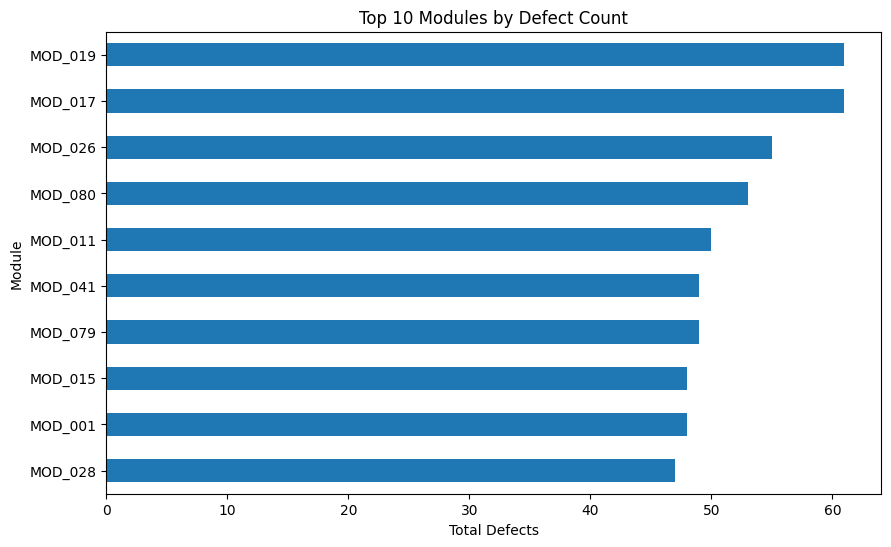

In [103]:
plt.figure(figsize=(10,6))

module_defects.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Modules by Defect Count")
plt.xlabel("Total Defects")
plt.ylabel("Module")

plt.show()

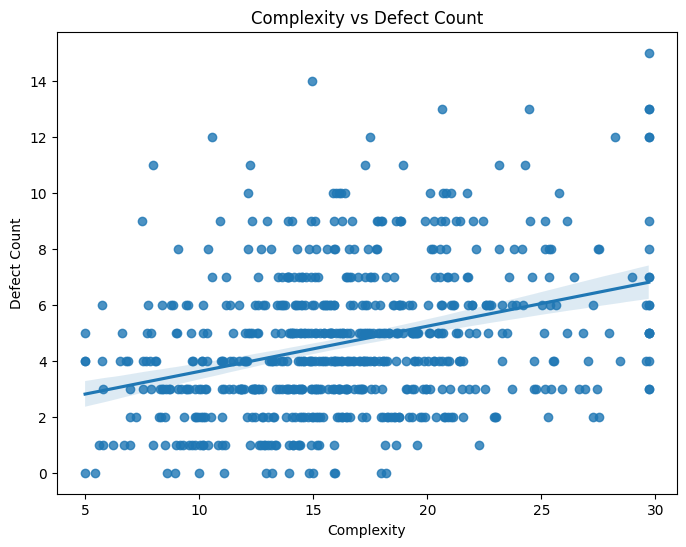

In [104]:
plt.figure(figsize=(8,6))

sns.regplot(
    data=final_df,
    x="complexity",
    y="defect_count"
)

plt.title("Complexity vs Defect Count")
plt.xlabel("Complexity")
plt.ylabel("Defect Count")

plt.show()

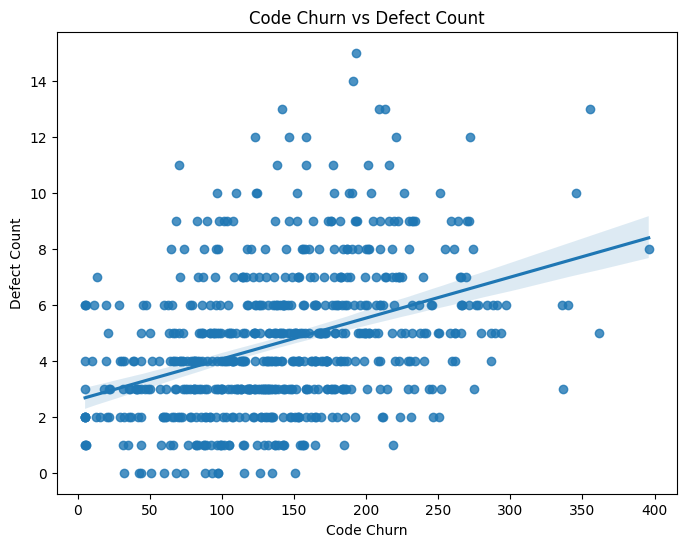

In [105]:
plt.figure(figsize=(8,6))

sns.regplot(
    data=final_df,
    x="churn",
    y="defect_count"
)

plt.title("Code Churn vs Defect Count")
plt.xlabel("Code Churn")
plt.ylabel("Defect Count")

plt.show()

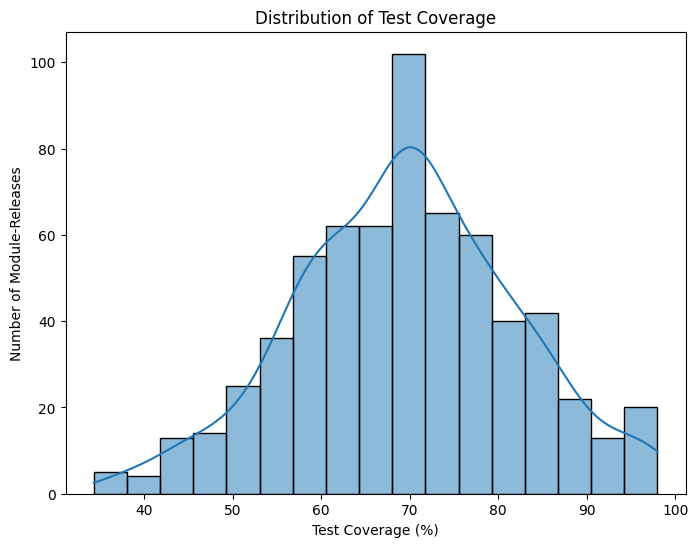

In [106]:
plt.figure(figsize=(8,6))

sns.histplot(
    final_df["test_coverage"],
    kde=True
)

plt.title("Distribution of Test Coverage")
plt.xlabel("Test Coverage (%)")
plt.ylabel("Number of Module-Releases")

plt.show()

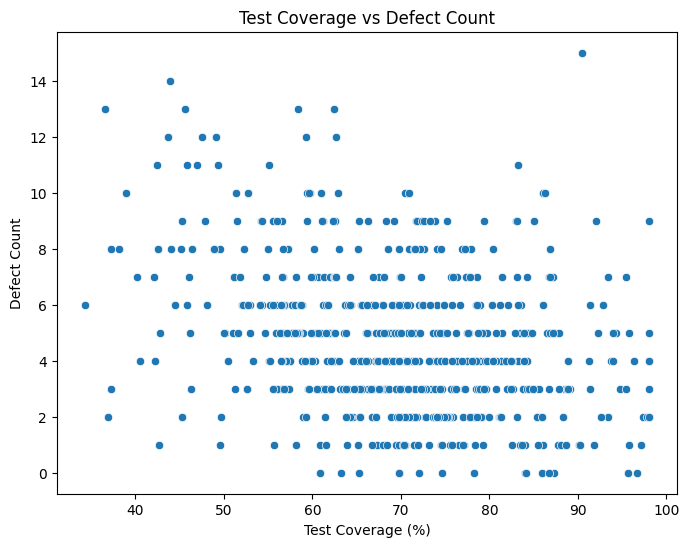

In [107]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=final_df,
    x="test_coverage",
    y="defect_count"
)

plt.title("Test Coverage vs Defect Count")
plt.xlabel("Test Coverage (%)")
plt.ylabel("Defect Count")

plt.show()

In [108]:
component_defects = (
    final_df
    .groupby("component")["defect_count"]
    .sum()
    .sort_values(
        ascending=False
    )
)

display(component_defects)

,defect_count
component,
Payments,373.0
Analytics,349.0
Search,345.0
User Management,329.0
API,320.0
Core,311.0
Notifications,300.0
Inventory,265.0
Reporting,220.0


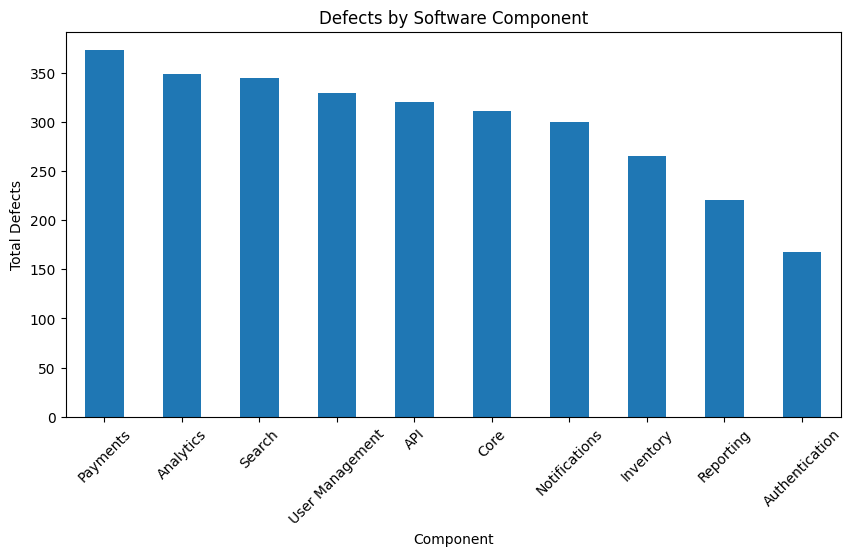

In [109]:
plt.figure(figsize=(10,5))

component_defects.plot(
    kind="bar"
)

plt.title("Defects by Software Component")
plt.xlabel("Component")
plt.ylabel("Total Defects")

plt.xticks(rotation=45)

plt.show()

In [112]:
print(final_df.columns.tolist())

['module', 'release', 'complexity', 'coupling', 'churn', 'test_coverage', 'component', 'language', 'size', 'defect_count', 'commit_count_x', 'contributors_x', 'changed_lines_x', 'commit_count_y', 'contributors_y', 'changed_lines_y']


In [113]:
print(final_df[["contributors_x", "contributors_y"]].head())

   contributors_x  contributors_y
0               8               8
1               5               5
2               1               1
3               9               9
4               6               6


In [114]:
final_df["contributors"] = final_df["contributors_x"]

final_df.drop(
    columns=["contributors_x", "contributors_y"],
    inplace=True
)

In [115]:
print("contributors" in final_df.columns)

True


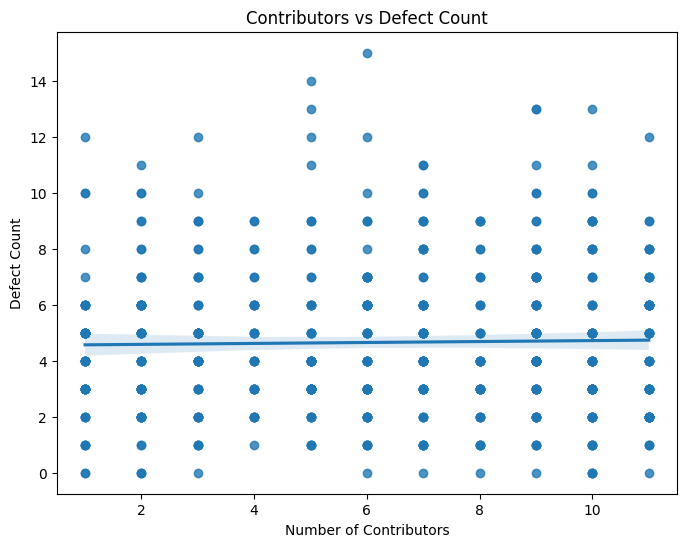

In [116]:
plt.figure(figsize=(8,6))

sns.regplot(
    data=final_df,
    x="contributors",
    y="defect_count"
)

plt.title("Contributors vs Defect Count")
plt.xlabel("Number of Contributors")
plt.ylabel("Defect Count")

plt.show()

In [119]:
print(final_df.columns.tolist())

['module', 'release', 'complexity', 'coupling', 'churn', 'test_coverage', 'component', 'language', 'size', 'defect_count', 'commit_count_x', 'changed_lines_x', 'commit_count_y', 'changed_lines_y', 'contributors']


In [120]:
final_df["commit_count"] = final_df["commit_count_x"]
final_df["changed_lines"] = final_df["changed_lines_x"]

final_df.drop(
    columns=[
        "commit_count_x",
        "commit_count_y",
        "changed_lines_x",
        "changed_lines_y"
    ],
    inplace=True
)

In [121]:
print(final_df.columns.tolist())

['module', 'release', 'complexity', 'coupling', 'churn', 'test_coverage', 'component', 'language', 'size', 'defect_count', 'contributors', 'commit_count', 'changed_lines']


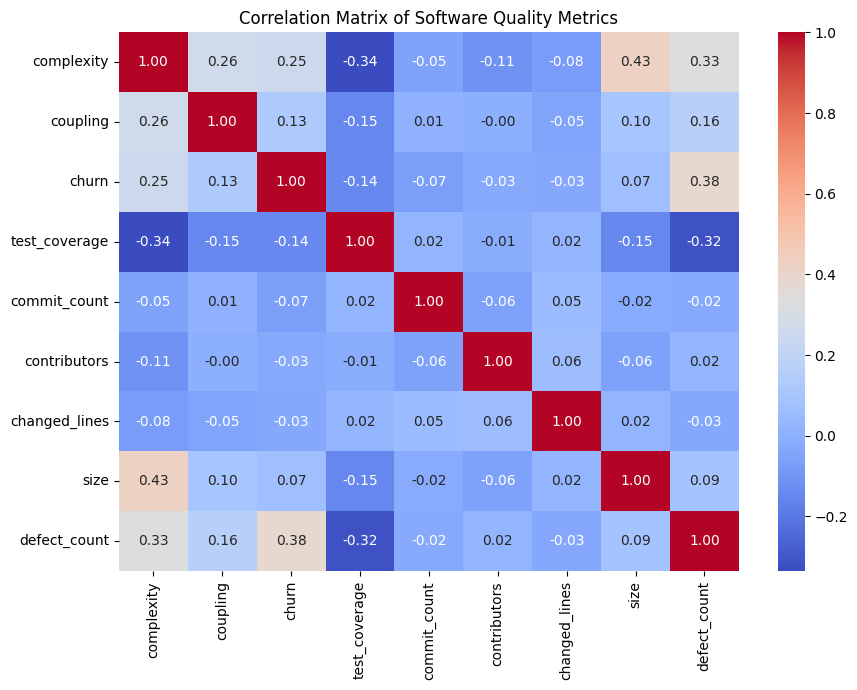

In [122]:
numeric_columns = [
    "complexity",
    "coupling",
    "churn",
    "test_coverage",
    "commit_count",
    "contributors",
    "changed_lines",
    "size",
    "defect_count"
]

correlation = final_df[numeric_columns].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Software Quality Metrics")
plt.show()

In [123]:
print(
    correlation["defect_count"]
    .sort_values(ascending=False)
)

defect_count     1.000000
churn            0.381444
complexity       0.331580
coupling         0.163624
size             0.091881
contributors     0.020510
commit_count    -0.022464
changed_lines   -0.027708
test_coverage   -0.318823
Name: defect_count, dtype: float64


In [124]:
print(
    correlation["defect_count"]
    .sort_values(ascending=False)
)

defect_count     1.000000
churn            0.381444
complexity       0.331580
coupling         0.163624
size             0.091881
contributors     0.020510
commit_count    -0.022464
changed_lines   -0.027708
test_coverage   -0.318823
Name: defect_count, dtype: float64


In [125]:
final_df["complexity_density"] = (
    final_df["complexity"] /
    final_df["size"].replace(0, np.nan)
)

final_df["complexity_density"] = final_df["complexity_density"].fillna(0)

In [126]:
final_df["testing_gap"] = (
    100 - final_df["test_coverage"]
)

In [128]:
final_df["defect_density"] = (
    final_df["defect_count"] /
    final_df["size"].replace(0, np.nan)
).fillna(0)

final_df["complexity_density"] = (
    final_df["complexity"] /
    final_df["size"].replace(0, np.nan)
).fillna(0)

final_df["testing_gap"] = (
    100 - final_df["test_coverage"]
)

In [129]:
display(
    final_df[
        [
            "defect_count",
            "defect_density",
            "complexity_density",
            "testing_gap"
        ]
    ].head()
)

,defect_count,defect_density,complexity_density,testing_gap
0,3.0,0.000218,0.001791,48.76
1,9.0,0.000654,0.001475,28.33
2,5.0,0.000363,0.002032,43.26
3,5.0,0.000363,0.001124,41.19
4,4.0,0.000290,0.001791,27.96


In [130]:
print(final_df.columns.tolist())

['module', 'release', 'complexity', 'coupling', 'churn', 'test_coverage', 'component', 'language', 'size', 'defect_count', 'contributors', 'commit_count', 'changed_lines', 'complexity_density', 'testing_gap', 'defect_density']


In [131]:
# Feature Engineering

final_df["defect_density"] = (
    final_df["defect_count"] /
    final_df["size"].replace(0, np.nan)
).fillna(0)

final_df["complexity_density"] = (
    final_df["complexity"] /
    final_df["size"].replace(0, np.nan)
).fillna(0)

final_df["testing_gap"] = (
    100 - final_df["test_coverage"]
)

# Check the new features
display(
    final_df[
        [
            "defect_count",
            "defect_density",
            "complexity_density",
            "testing_gap"
        ]
    ].head()
)

,defect_count,defect_density,complexity_density,testing_gap
0,3.0,0.000218,0.001791,48.76
1,9.0,0.000654,0.001475,28.33
2,5.0,0.000363,0.002032,43.26
3,5.0,0.000363,0.001124,41.19
4,4.0,0.000290,0.001791,27.96


In [132]:
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_regression

# Input features
numeric_features = [
    "complexity",
    "coupling",
    "churn",
    "test_coverage",
    "commit_count",
    "contributors",
    "changed_lines",
    "size",
    "complexity_density",
    "testing_gap"
]

categorical_features = [
    "component",
    "language"
]

X = final_df[numeric_features + categorical_features]
y = final_df["defect_count"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Feature selection on numerical features
selector = SelectKBest(
    score_func=f_regression,
    k=min(6, len(numeric_features))
)

selector.fit(
    X_train[numeric_features],
    y_train
)

selected_features = [
    feature
    for feature, selected in zip(
        numeric_features,
        selector.get_support()
    )
    if selected
]

print("Selected Features:")
print(selected_features)

# Feature scores
feature_scores = pd.DataFrame({
    "Feature": numeric_features,
    "Score": selector.scores_
}).sort_values(
    "Score",
    ascending=False
)

display(feature_scores)

Selected Features:
['complexity', 'coupling', 'churn', 'test_coverage', 'complexity_density', 'testing_gap']


,Feature,Score
2,churn,81.202640
0,complexity,63.248357
3,test_coverage,56.221544
9,testing_gap,56.221544
1,coupling,12.670064
8,complexity_density,4.746906
7,size,4.002823
6,changed_lines,1.131949
5,contributors,0.609711
4,commit_count,0.382516


In [133]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Use selected numerical features + categorical features
model_features = selected_features + categorical_features

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            selected_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

# Random Forest Regression
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

# Complete pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ]
)

# Train
pipeline.fit(
    X_train[model_features],
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [134]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prediction
y_pred = pipeline.predict(
    X_test[model_features]
)

# Performance
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-------------------------")
print("MAE :", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²  :", round(r2, 3))

MODEL PERFORMANCE
-------------------------
MAE : 1.687
RMSE: 2.174
R²  : 0.315


In [135]:
# Get feature names after encoding
encoded_features = (
    pipeline
    .named_steps["preprocessing"]
    .named_transformers_["cat"]
    .named_steps["encoder"]
    .get_feature_names_out(categorical_features)
)

all_feature_names = np.concatenate([
    selected_features,
    encoded_features
])

# Get importance
importance_values = (
    pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importance_values
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(10))

,Feature,Importance
2,churn,0.234544
0,complexity,0.152005
5,testing_gap,0.130339
3,test_coverage,0.117759
4,complexity_density,0.115562
1,coupling,0.113126
14,component_Search,0.015712
20,language_Python,0.015087
8,component_Authentication,0.010437
19,language_JavaScript,0.010055


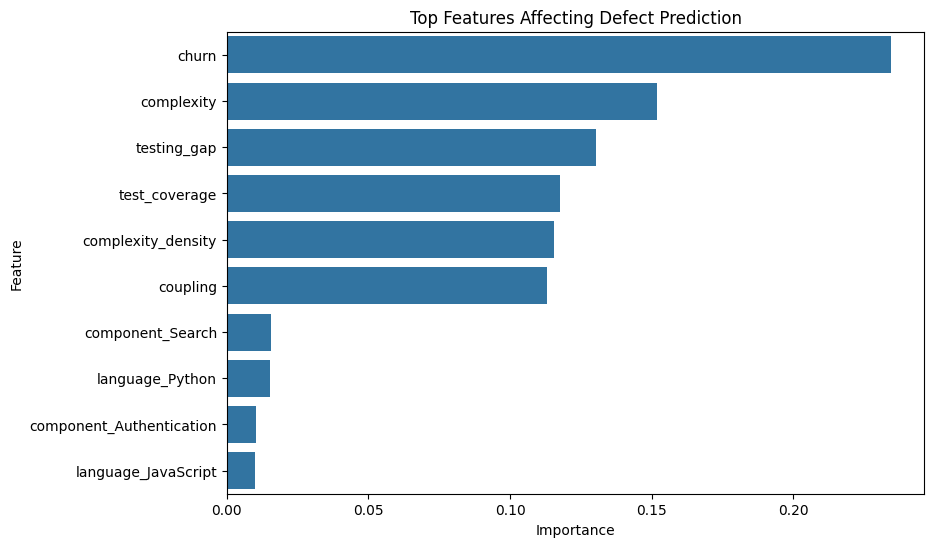

In [136]:
plt.figure(figsize=(9,6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top Features Affecting Defect Prediction")
plt.show()

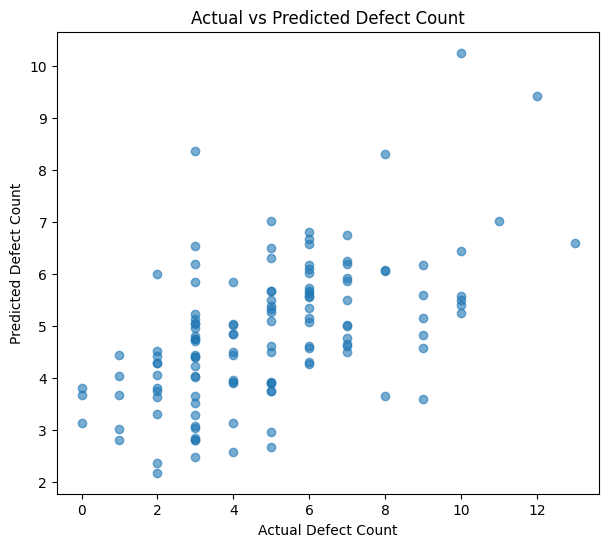

In [137]:
plt.figure(figsize=(7,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Actual Defect Count")
plt.ylabel("Predicted Defect Count")
plt.title("Actual vs Predicted Defect Count")

plt.show()

In [138]:
final_df.to_csv(
    "software_quality_cleaned.csv",
    index=False
)

feature_scores.to_csv(
    "feature_selection_results.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("All required files saved successfully.")

All required files saved successfully.


In [139]:
from google.colab import files

files.download("software_quality_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>